In [6]:

!pip install -q tensorflow pandas numpy scikit-learn


In [7]:

import os
import re
import zipfile
import numpy as np
import pandas as pd
import tensorflow as tf

from google.colab import files
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)
print("All libraries imported successfully!")


TensorFlow version: 2.21.0
All libraries imported successfully!


In [8]:

zip_path = "/content/archive (1).zip"

if not os.path.exists(zip_path):
    print("Please upload your Kaggle ZIP file.")
    uploaded = files.upload()
    zip_files = [
        name for name in uploaded
        if name.lower().endswith(".zip")
    ]
    if not zip_files:
        raise ValueError("Please upload a ZIP dataset.")
    zip_path = "/content/" + zip_files[0]

extract_path = "/content/next_word_dataset"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted successfully!\n")
for root, dirs, filenames in os.walk(extract_path):
    for name in filenames:
        print(os.path.join(root, name))


Dataset extracted successfully!

/content/next_word_dataset/1661-0.txt


In [9]:

sentences = []

for root, dirs, filenames in os.walk(extract_path):
    for name in filenames:
        path = os.path.join(root, name)

        if name.lower().endswith(".txt"):
            with open(
                path, "r", encoding="utf-8", errors="ignore"
            ) as f:
                text_data = f.read()

            # Split text into sentence-like pieces
            pieces = re.split(r"(?<=[.!?])\s+|\n+", text_data)
            sentences.extend(
                s.strip() for s in pieces if len(s.split()) >= 2
            )

        elif name.lower().endswith(".csv"):
            try:
                df = pd.read_csv(path, on_bad_lines="skip")
                columns = [
                    c for c in df.columns
                    if c.lower() in [
                        "text", "sentence", "content",
                        "review", "story"
                    ]
                ]

                if not columns:
                    columns = [
                        c for c in df.columns
                        if df[c].dtype == "object"
                    ]

                if columns:
                    for value in df[columns[0]].dropna().astype(str):
                        pieces = re.split(r"(?<=[.!?])\s+|\n+", value)
                        sentences.extend(
                            s.strip() for s in pieces
                            if len(s.split()) >= 2
                        )
            except Exception as e:
                print("Could not read:", name, e)

# Basic cleanup
clean_sentences = []

for s in sentences:
    s = s.lower()
    s = re.sub(r"[^a-z0-9'\s]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()

    if len(s.split()) >= 2:
        clean_sentences.append(s)

# Remove duplicates and limit the dataset
clean_sentences = list(dict.fromkeys(clean_sentences))
clean_sentences = clean_sentences[:10000]

print("Total sentences loaded:", len(clean_sentences))
print("\nFirst 10 sentences:")
for s in clean_sentences[:10]:
    print("-", s)

if len(clean_sentences) < 100:
    print(
        "\nWarning: Very few sentences were found. "
        "Check the file list and text column."
    )


Total sentences loaded: 10000

First 10 sentences:
- project gutenberg's the adventures of sherlock holmes by arthur conan doyle
- this ebook is for the use of anyone anywhere at no cost and with
- almost no restrictions whatsoever
- you may copy it give it away or
- re use it under the terms of the project gutenberg license included
- with this ebook or online at www gutenberg net
- title the adventures of sherlock holmes
- author arthur conan doyle
- release date november 29 2002 ebook 1661
- last updated may 20 2019


In [10]:

# Split sentences into training and testing data
train_sentences, test_sentences = train_test_split(
    clean_sentences,
    test_size=0.20,
    random_state=42
)

# Build vocabulary using training data only
tokenizer = Tokenizer(
    num_words=8000,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(train_sentences)

vocab_size = min(
    8000, len(tokenizer.word_index) + 1
)

print("Training sentences:", len(train_sentences))
print("Testing sentences:", len(test_sentences))
print("Vocabulary size:", vocab_size)
print("\nFirst 20 word IDs:")

for word, word_id in list(tokenizer.word_index.items())[:20]:
    print(word, ":", word_id)


Training sentences: 8000
Testing sentences: 2000
Vocabulary size: 6537

First 20 word IDs:
<OOV> : 1
the : 2
and : 3
i : 4
of : 5
to : 6
a : 7
in : 8
that : 9
it : 10
he : 11
you : 12
was : 13
his : 14
is : 15
my : 16
have : 17
as : 18
had : 19
with : 20


In [11]:

MAX_LEN = 15

def create_sequences(sentence_list):
    sequences = []

    for sentence in sentence_list:
        ids = tokenizer.texts_to_sequences([sentence])[0]

        # Generate prefixes with the next word as target
        for i in range(1, len(ids)):
            sequences.append(ids[max(0, i - MAX_LEN):i + 1])

    if not sequences:
        raise ValueError(
            "No sequences created. Check your dataset."
        )

    padded = pad_sequences(
        sequences,
        maxlen=MAX_LEN + 1,
        padding="pre",
        truncating="pre"
    )

    X = padded[:, :-1]
    y = padded[:, -1]

    # Ignore targets that are padding or outside vocabulary
    valid = (y > 0) & (y < vocab_size)
    return X[valid], y[valid]

X_train, y_train = create_sequences(train_sentences)
X_test, y_test = create_sequences(test_sentences)

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)
print("Testing input shape:", X_test.shape)
print("Testing target shape:", y_test.shape)


Training input shape: (60982, 15)
Training target shape: (60982,)
Testing input shape: (15202, 15)
Testing target shape: (15202,)


In [12]:

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(128),
    Dropout(0.2),
    Dense(vocab_size, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=[
        "sparse_categorical_accuracy",
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5, name="top5_accuracy"
        )
    ]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [15]:

# Rebuild the model
tf.keras.backend.clear_session()

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        input_length=MAX_LEN
    ),
    LSTM(64),
    Dropout(0.2),
    Dense(vocab_size, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=[
        "sparse_categorical_accuracy",
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5, name="top5_accuracy"
        )
    ]
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:

# Check data shapes and types
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Vocabulary size:", vocab_size)
print("Maximum input ID:", int(np.max(X_train)))
print("Maximum target ID:", int(np.max(y_train)))

# Ensure the data uses integer IDs
X_train = X_train.astype("int32")
y_train = y_train.astype("int32")

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

print("Training completed successfully!")


X_train: (60982, 15)
y_train: (60982,)
Vocabulary size: 6537
Maximum input ID: 6536
Maximum target ID: 6536
Epoch 1/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 6.5425 - sparse_categorical_accuracy: 0.0542 - top5_accuracy: 0.1640 - val_loss: 6.3375 - val_sparse_categorical_accuracy: 0.0539 - val_top5_accuracy: 0.1687
Epoch 2/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 6.1898 - sparse_categorical_accuracy: 0.0656 - top5_accuracy: 0.1786 - val_loss: 6.2288 - val_sparse_categorical_accuracy: 0.0700 - val_top5_accuracy: 0.2023
Epoch 3/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 5.9597 - sparse_categorical_accuracy: 0.0808 - top5_accuracy: 0.2155 - val_loss: 6.0780 - val_sparse_categorical_accuracy: 0.0830 - val_top5_accuracy: 0.2392
Epoch 4/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 5.7479 - sparse_categorical_accuracy: 0.1022 - top5_accuracy: 0.2534 - val_loss: 5.9873 - val_sparse_categorical_accuracy: 0.1074 - val_top5_accuracy: 0.2648
Epoch 5/10
858/858 ━

In [17]:

test_results = model.evaluate(
    X_test,
    y_test,
    verbose=0,
    return_dict=True
)

print("MODEL EVALUATION")
print("-----------------------")
print("Test Loss:", round(test_results["loss"], 4))
print(
    "Top-1 Accuracy:",
    round(test_results["sparse_categorical_accuracy"] * 100, 2),
    "%"
)
print(
    "Top-5 Accuracy:",
    round(test_results["top5_accuracy"] * 100, 2),
    "%"
)


MODEL EVALUATION
-----------------------
Test Loss: 5.9244
Top-1 Accuracy: 12.49 %
Top-5 Accuracy: 29.09 %


In [18]:

test_phrases = [
    "i want to",
    "how are you",
    "machine learning is",
    "the sun is",
    "i am going to"
]

for phrase in test_phrases:
    predict_next_words(phrase, top_k=5)


NameError: name 'predict_next_words' is not defined

In [19]:

def predict_next_words(phrase, top_k=5):
    import re
    import numpy as np
    from tensorflow.keras.preprocessing.sequence import pad_sequences

    phrase = phrase.lower()
    phrase = re.sub(r"[^a-z0-9'\s]", " ", phrase)
    phrase = re.sub(r"\s+", " ", phrase).strip()

    # Convert input words to numerical IDs
    ids = tokenizer.texts_to_sequences([phrase])[0]

    if not ids:
        print("No recognized words. Try another phrase.")
        return

    # Prepare input for the LSTM
    x = pad_sequences(
        [ids],
        maxlen=MAX_LEN,
        padding="pre",
        truncating="pre"
    )

    # Predict probabilities
    probabilities = model.predict(x, verbose=0)[0].copy()
    probabilities[0] = 0

    # Get top predicted words
    top_ids = np.argsort(probabilities)[::-1][:top_k]

    print("\nInput phrase:", phrase)
    print("Predicted next words:")

    for word_id in top_ids:
        word = tokenizer.index_word.get(int(word_id), "<unknown>")
        print(f"{word}: {probabilities[word_id] * 100:.2f}%")


In [20]:

test_phrases = [
    "i want to",
    "how are you",
    "machine learning is",
    "the sun is",
    "i am going to"
]

for phrase in test_phrases:
    predict_next_words(phrase, top_k=5)



Input phrase: i want to
Predicted next words:
be: 8.21%
the: 6.56%
me: 2.25%
a: 2.04%
have: 1.93%

Input phrase: how are you
Predicted next words:
have: 7.94%
be: 3.71%
not: 3.02%
see: 2.93%
you: 2.37%

Input phrase: machine learning is
Predicted next words:
a: 11.50%
the: 6.61%
in: 4.62%
and: 2.62%
his: 2.62%

Input phrase: the sun is
Predicted next words:
a: 4.43%
the: 3.43%
and: 1.47%
in: 1.45%
which: 1.31%

Input phrase: i am going to
Predicted next words:
the: 11.66%
be: 7.47%
me: 2.72%
a: 2.65%
my: 2.28%


In [23]:

phrase = input("Enter a phrase: ")
predict_next_words(phrase, top_k=5)


Enter a phrase: I want to

Input phrase: i want to
Predicted next words:
be: 8.21%
the: 6.56%
me: 2.25%
a: 2.04%
have: 1.93%


In [22]:

results = model.evaluate(
    X_test,
    y_test,
    verbose=0,
    return_dict=True
)

print("Test Loss:", round(results["loss"], 4))
print(
    "Top-1 Accuracy:",
    round(results["sparse_categorical_accuracy"] * 100, 2),
    "%"
)
print(
    "Top-5 Accuracy:",
    round(results["top5_accuracy"] * 100, 2),
    "%"
)


Test Loss: 5.9244
Top-1 Accuracy: 12.49 %
Top-5 Accuracy: 29.09 %


In [24]:

# Improved LSTM model
tf.keras.backend.clear_session()

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=100
    ),
    LSTM(128),
    Dropout(0.2),
    Dense(vocab_size, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=[
        "sparse_categorical_accuracy",
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5, name="top5_accuracy"
        )
    ]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [25]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.10,
    callbacks=[early_stop],
    verbose=1
)

print("Improved model training completed!")


Epoch 1/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 6.4975 - sparse_categorical_accuracy: 0.0583 - top5_accuracy: 0.1650 - val_loss: 6.2733 - val_sparse_categorical_accuracy: 0.0666 - val_top5_accuracy: 0.1802
Epoch 2/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 5.9991 - sparse_categorical_accuracy: 0.0839 - top5_accuracy: 0.2198 - val_loss: 5.9438 - val_sparse_categorical_accuracy: 0.1040 - val_top5_accuracy: 0.2658
Epoch 3/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 5.6115 - sparse_categorical_accuracy: 0.1150 - top5_accuracy: 0.2798 - val_loss: 5.8163 - val_sparse_categorical_accuracy: 0.1203 - val_top5_accuracy: 0.2876
Epoch 4/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 5.3678 - sparse_categorical_accuracy: 0.1323 - top5_accuracy: 0.3033 - val_loss: 5.7675 - val_sparse_categorical_accuracy: 0.1277 - val_top5_accuracy: 0.3015
Epoch 5/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 5.1677 - sparse_categorical_accuracy: 0.1410 - top5_accuracy: 0.3213

In [26]:

results = model.evaluate(
    X_test,
    y_test,
    verbose=0,
    return_dict=True
)

print("New Test Loss:", round(results["loss"], 4))
print(
    "New Top-1 Accuracy:",
    round(results["sparse_categorical_accuracy"] * 100, 2),
    "%"
)
print(
    "New Top-5 Accuracy:",
    round(results["top5_accuracy"] * 100, 2),
    "%"
)


New Test Loss: 5.8006
New Top-1 Accuracy: 13.15 %
New Top-5 Accuracy: 30.34 %


In [27]:
print("Total sentences used:", len(sentences))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Vocabulary size:", vocab_size)

Total sentences used: 12641
Training samples: 60982
Testing samples: 15202
Vocabulary size: 6537


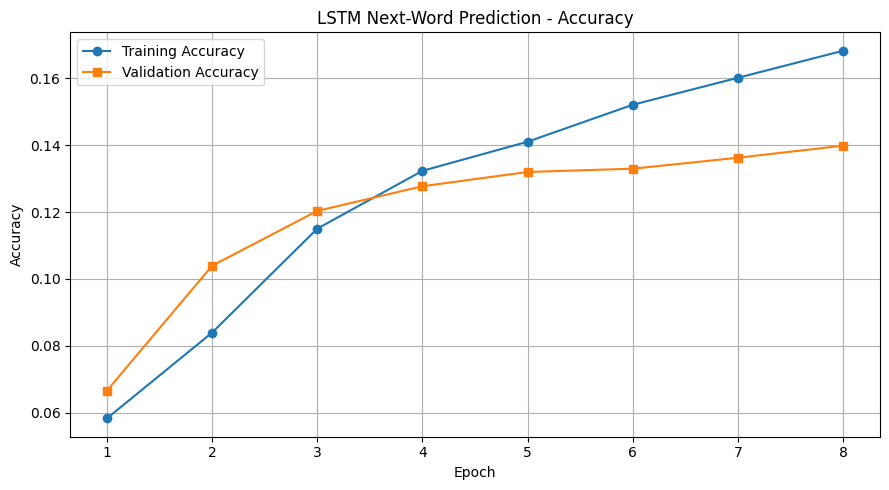

In [28]:

import matplotlib.pyplot as plt

# Get accuracy values from training history
train_accuracy = history.history[
    "sparse_categorical_accuracy"
]
val_accuracy = history.history[
    "val_sparse_categorical_accuracy"
]

epochs = range(1, len(train_accuracy) + 1)

# Plot accuracy graph
plt.figure(figsize=(9, 5))

plt.plot(
    epochs, train_accuracy,
    marker="o", label="Training Accuracy"
)

plt.plot(
    epochs, val_accuracy,
    marker="s", label="Validation Accuracy"
)

plt.title("LSTM Next-Word Prediction - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
